In [1]:
!nvidia-smi

Thu Oct  8 14:49:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   64C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
HOME = os.getcwd()
print(HOME)

/kaggle/working


In [3]:
# Pip install method (recommended)

!pip install ultralytics 

from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7087.1/8156.9 GB disk)


In [5]:
from ultralytics import YOLO

from IPython.display import display, Image

In [6]:
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

user_secrets = UserSecretsClient()
api_key = user_secrets.get_secret("ROBOFLOW_API_KEY")

rf = Roboflow(api_key=api_key)
project = rf.workspace("georgia-silva").project("libras-proprio")
version = project.version(2)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Libras-proprio-2 in yolov8:: 100%|██████████| 5658/5658 [00:00<00:00, 10465.61it/s]


In [9]:
!ls /kaggle/working/datasets/Libras-proprio-2


data.yaml  README.dataset.txt  README.roboflow.txt  test  train  valid


Modify data.yaml with the correct path:

test: /kaggle/working/datasets/Libras-proprio-2/test/images

train: /kaggle/working/datasets/Libras-proprio-2/train/images

val: /kaggle/working/datasets/Libras-proprio-2/valid/images


In [11]:
MODEL = 'yolov8n.pt'
IMG_SIZE = 640
EPOCHS = 70
HALF=True

In [12]:
%cd {HOME}
!yolo task=detect mode=train model={MODEL} data={dataset.location}/data.yaml epochs={EPOCHS} imgsz={IMG_SIZE} plots=True fliplr=0.0 

/kaggle/working
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Libras-proprio-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=70, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opse

In [13]:
import glob

last_run = sorted(glob.glob(f'{HOME}/runs/detect/train*'))[-1]
print(f"Usando a pasta: {last_run}")

Usando a pasta: /kaggle/working/runs/detect/train-2


In [14]:
!ls {last_run}

args.yaml			 results.csv	      val_batch0_labels.jpg
BoxF1_curve.png			 results.png	      val_batch0_pred.jpg
BoxP_curve.png			 train_batch0.jpg     val_batch1_labels.jpg
BoxPR_curve.png			 train_batch1.jpg     val_batch1_pred.jpg
BoxR_curve.png			 train_batch2.jpg     val_batch2_labels.jpg
confusion_matrix_normalized.png  train_batch9300.jpg  val_batch2_pred.jpg
confusion_matrix.png		 train_batch9301.jpg  weights
labels.jpg			 train_batch9302.jpg


In [15]:
   %cd {HOME}
   !yolo task=detect mode=val model={last_run}/weights/best.pt data={dataset.location}/data.yaml agnostic_nms=True plots=True

/kaggle/working
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,009,743 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 863.1±162.6 MB/s, size: 25.6 KB)
val: Scanning /kaggle/working/Libras-proprio-2/valid/labels.cache... 238 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 238/238 52.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.9it/s 3.1s0.1s
                   all        238        236      0.937      0.967      0.958      0.622
                     A         24         24      0.977          1      0.995      0.682
                     B         19         19      0.974          1      0.995      0.743
                     C         31         31      0.987          1      0.995      0.697
                     D         27         27      0.946          1      0.995      0.619
             

/kaggle/working


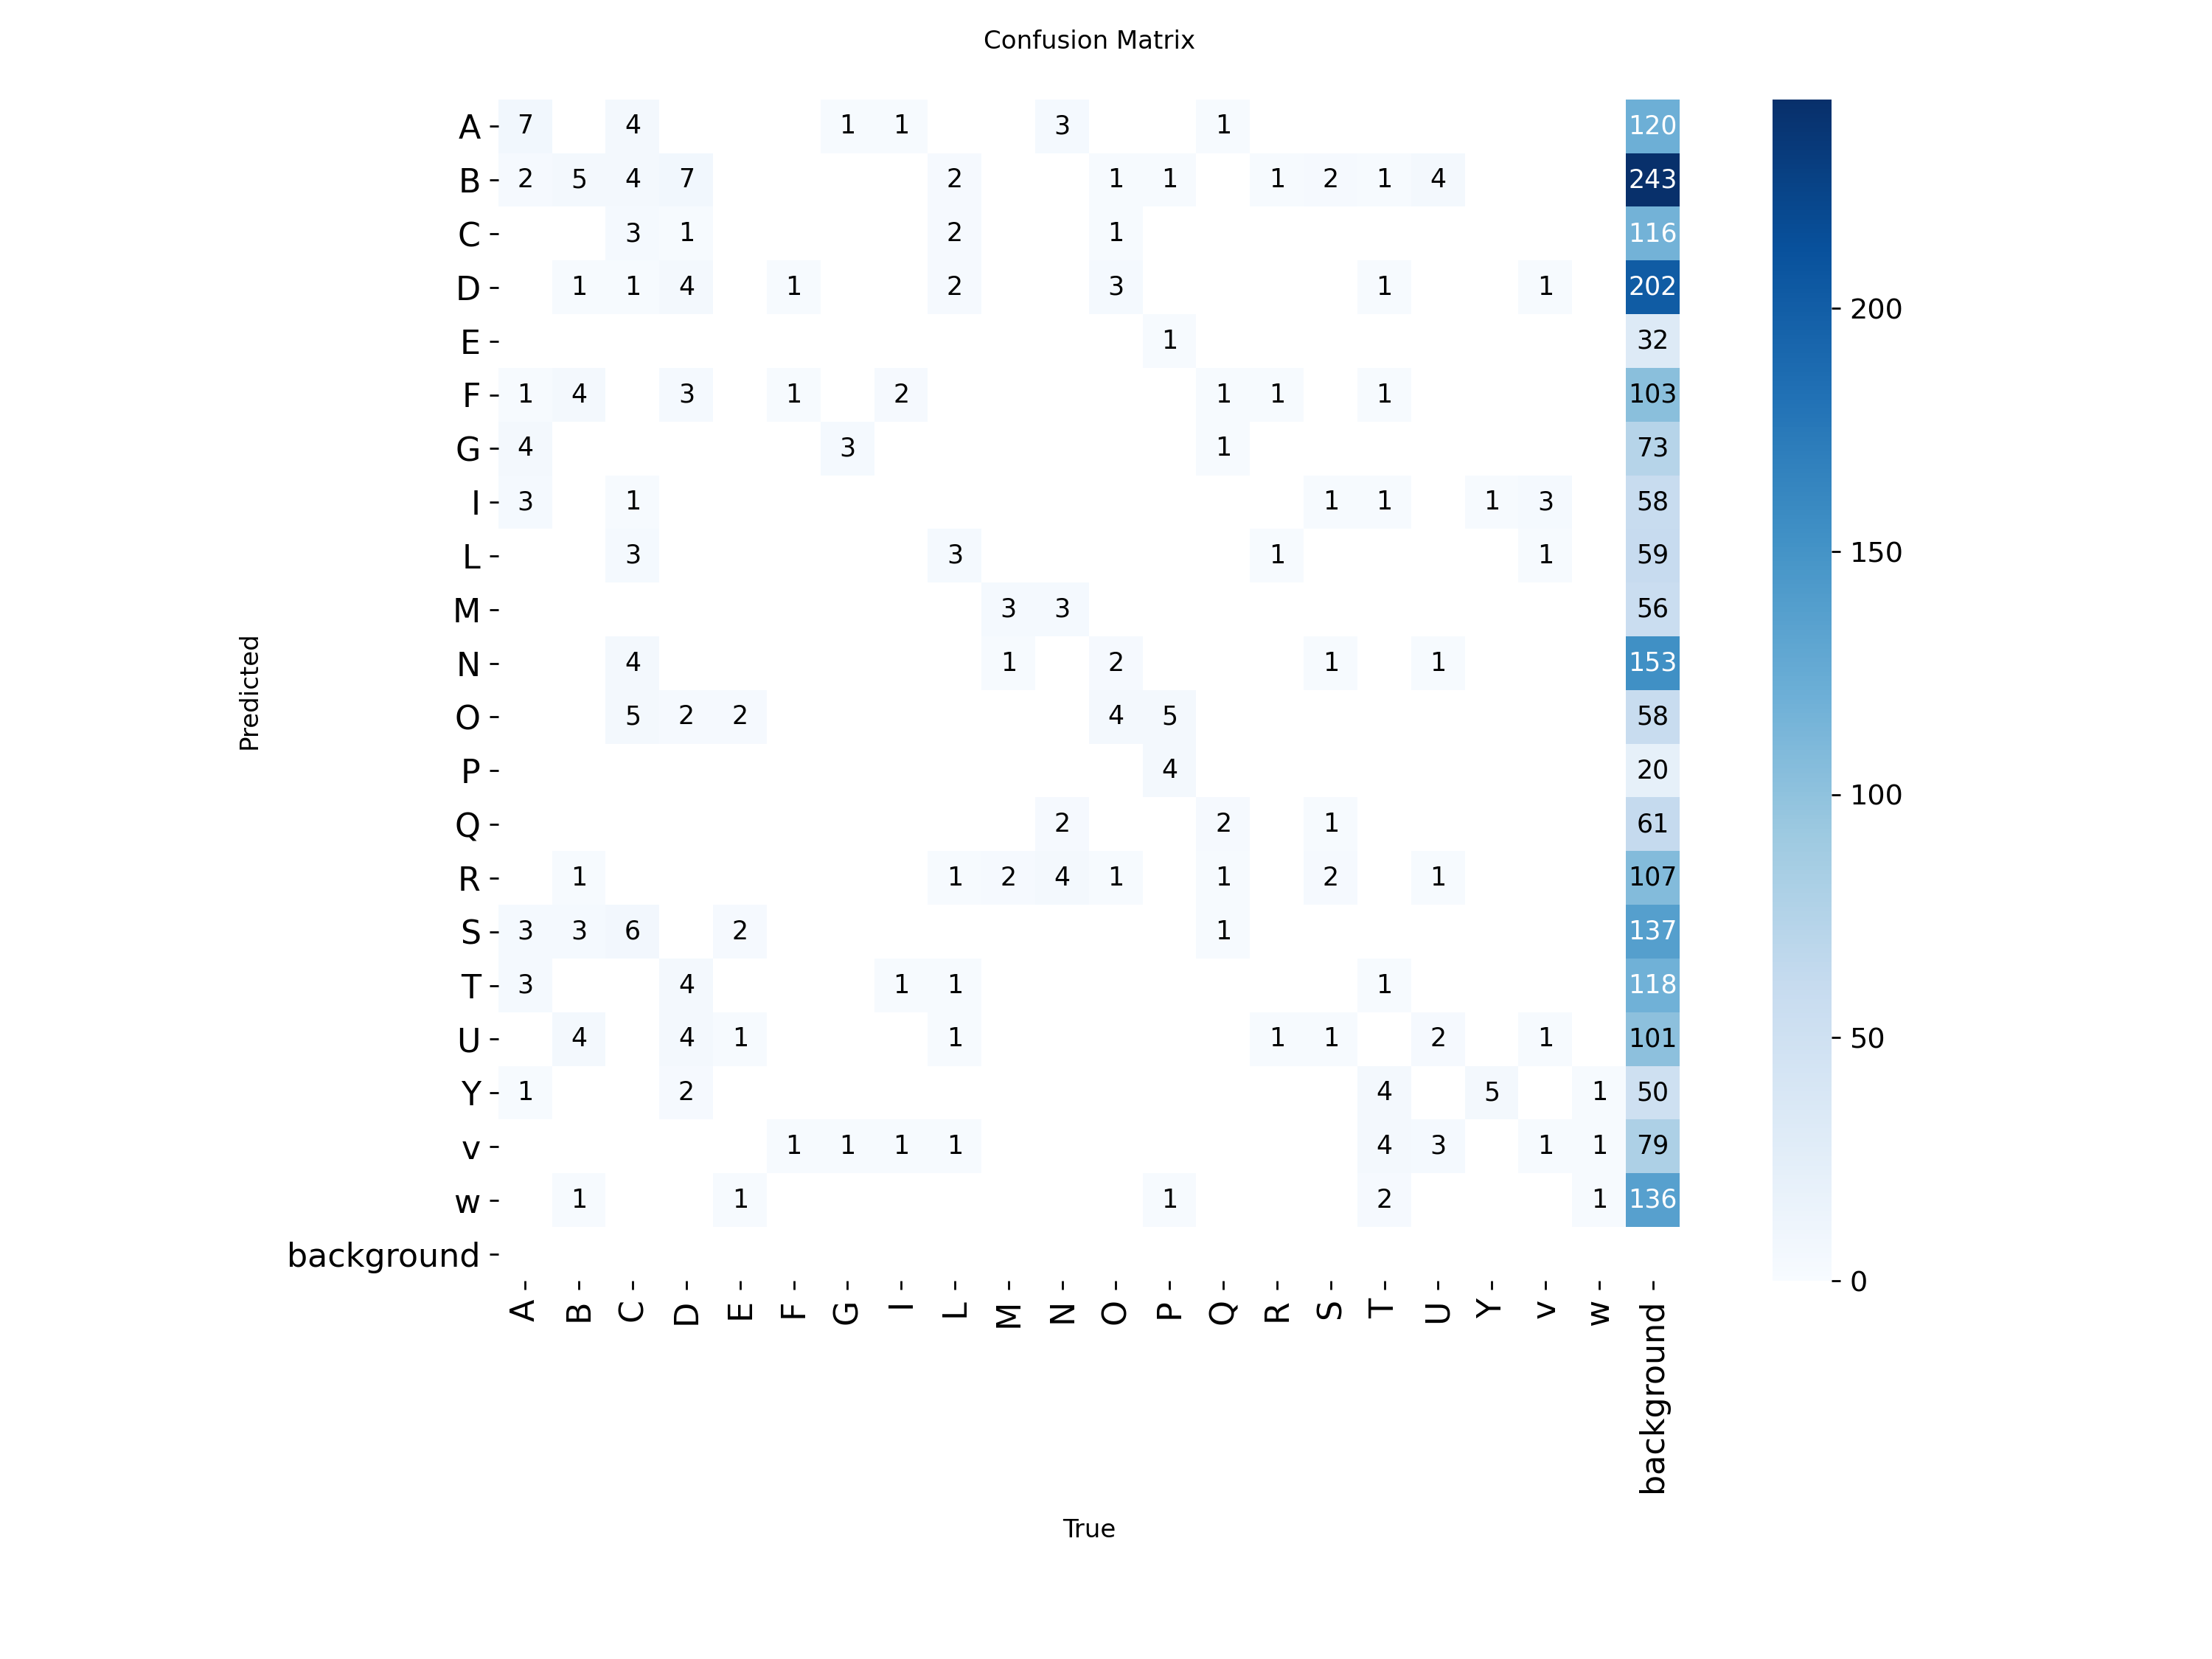

In [16]:
%cd {HOME}
Image(filename=f'{last_run}/confusion_matrix.png', width=600)

In [17]:
%cd {HOME}
!yolo task=detect mode=val model={last_run}/weights/best.pt data={dataset.location}/data.yaml conf=0.25 plots=True
!ls {HOME}/runs/detect

/kaggle/working
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,009,743 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1049.8±248.6 MB/s, size: 27.4 KB)
val: Scanning /kaggle/working/Libras-proprio-2/valid/labels.cache... 238 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 238/238 43.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.9it/s 3.1s0.1s
                   all        238        236      0.972      0.967      0.958      0.615
                     A         24         24          1          1      0.995      0.682
                     B         19         19          1          1      0.995      0.743
                     C         31         31          1          1      0.995      0.692
                     D         27         27      0.964          1      0.995      0.613
            

/kaggle/working
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,009,743 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 929.7±176.6 MB/s, size: 26.9 KB)
val: Scanning /kaggle/working/Libras-proprio-2/valid/labels.cache... 238 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 238/238 49.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 5.0it/s 3.0s0.1s
                   all        238        236      0.972      0.967      0.958      0.615
                     A         24         24          1          1      0.995      0.682
                     B         19         19          1          1      0.995      0.743
                     C         31         31          1          1      0.995      0.692
                     D         27         27      0.964          1      0.995      0.613
             

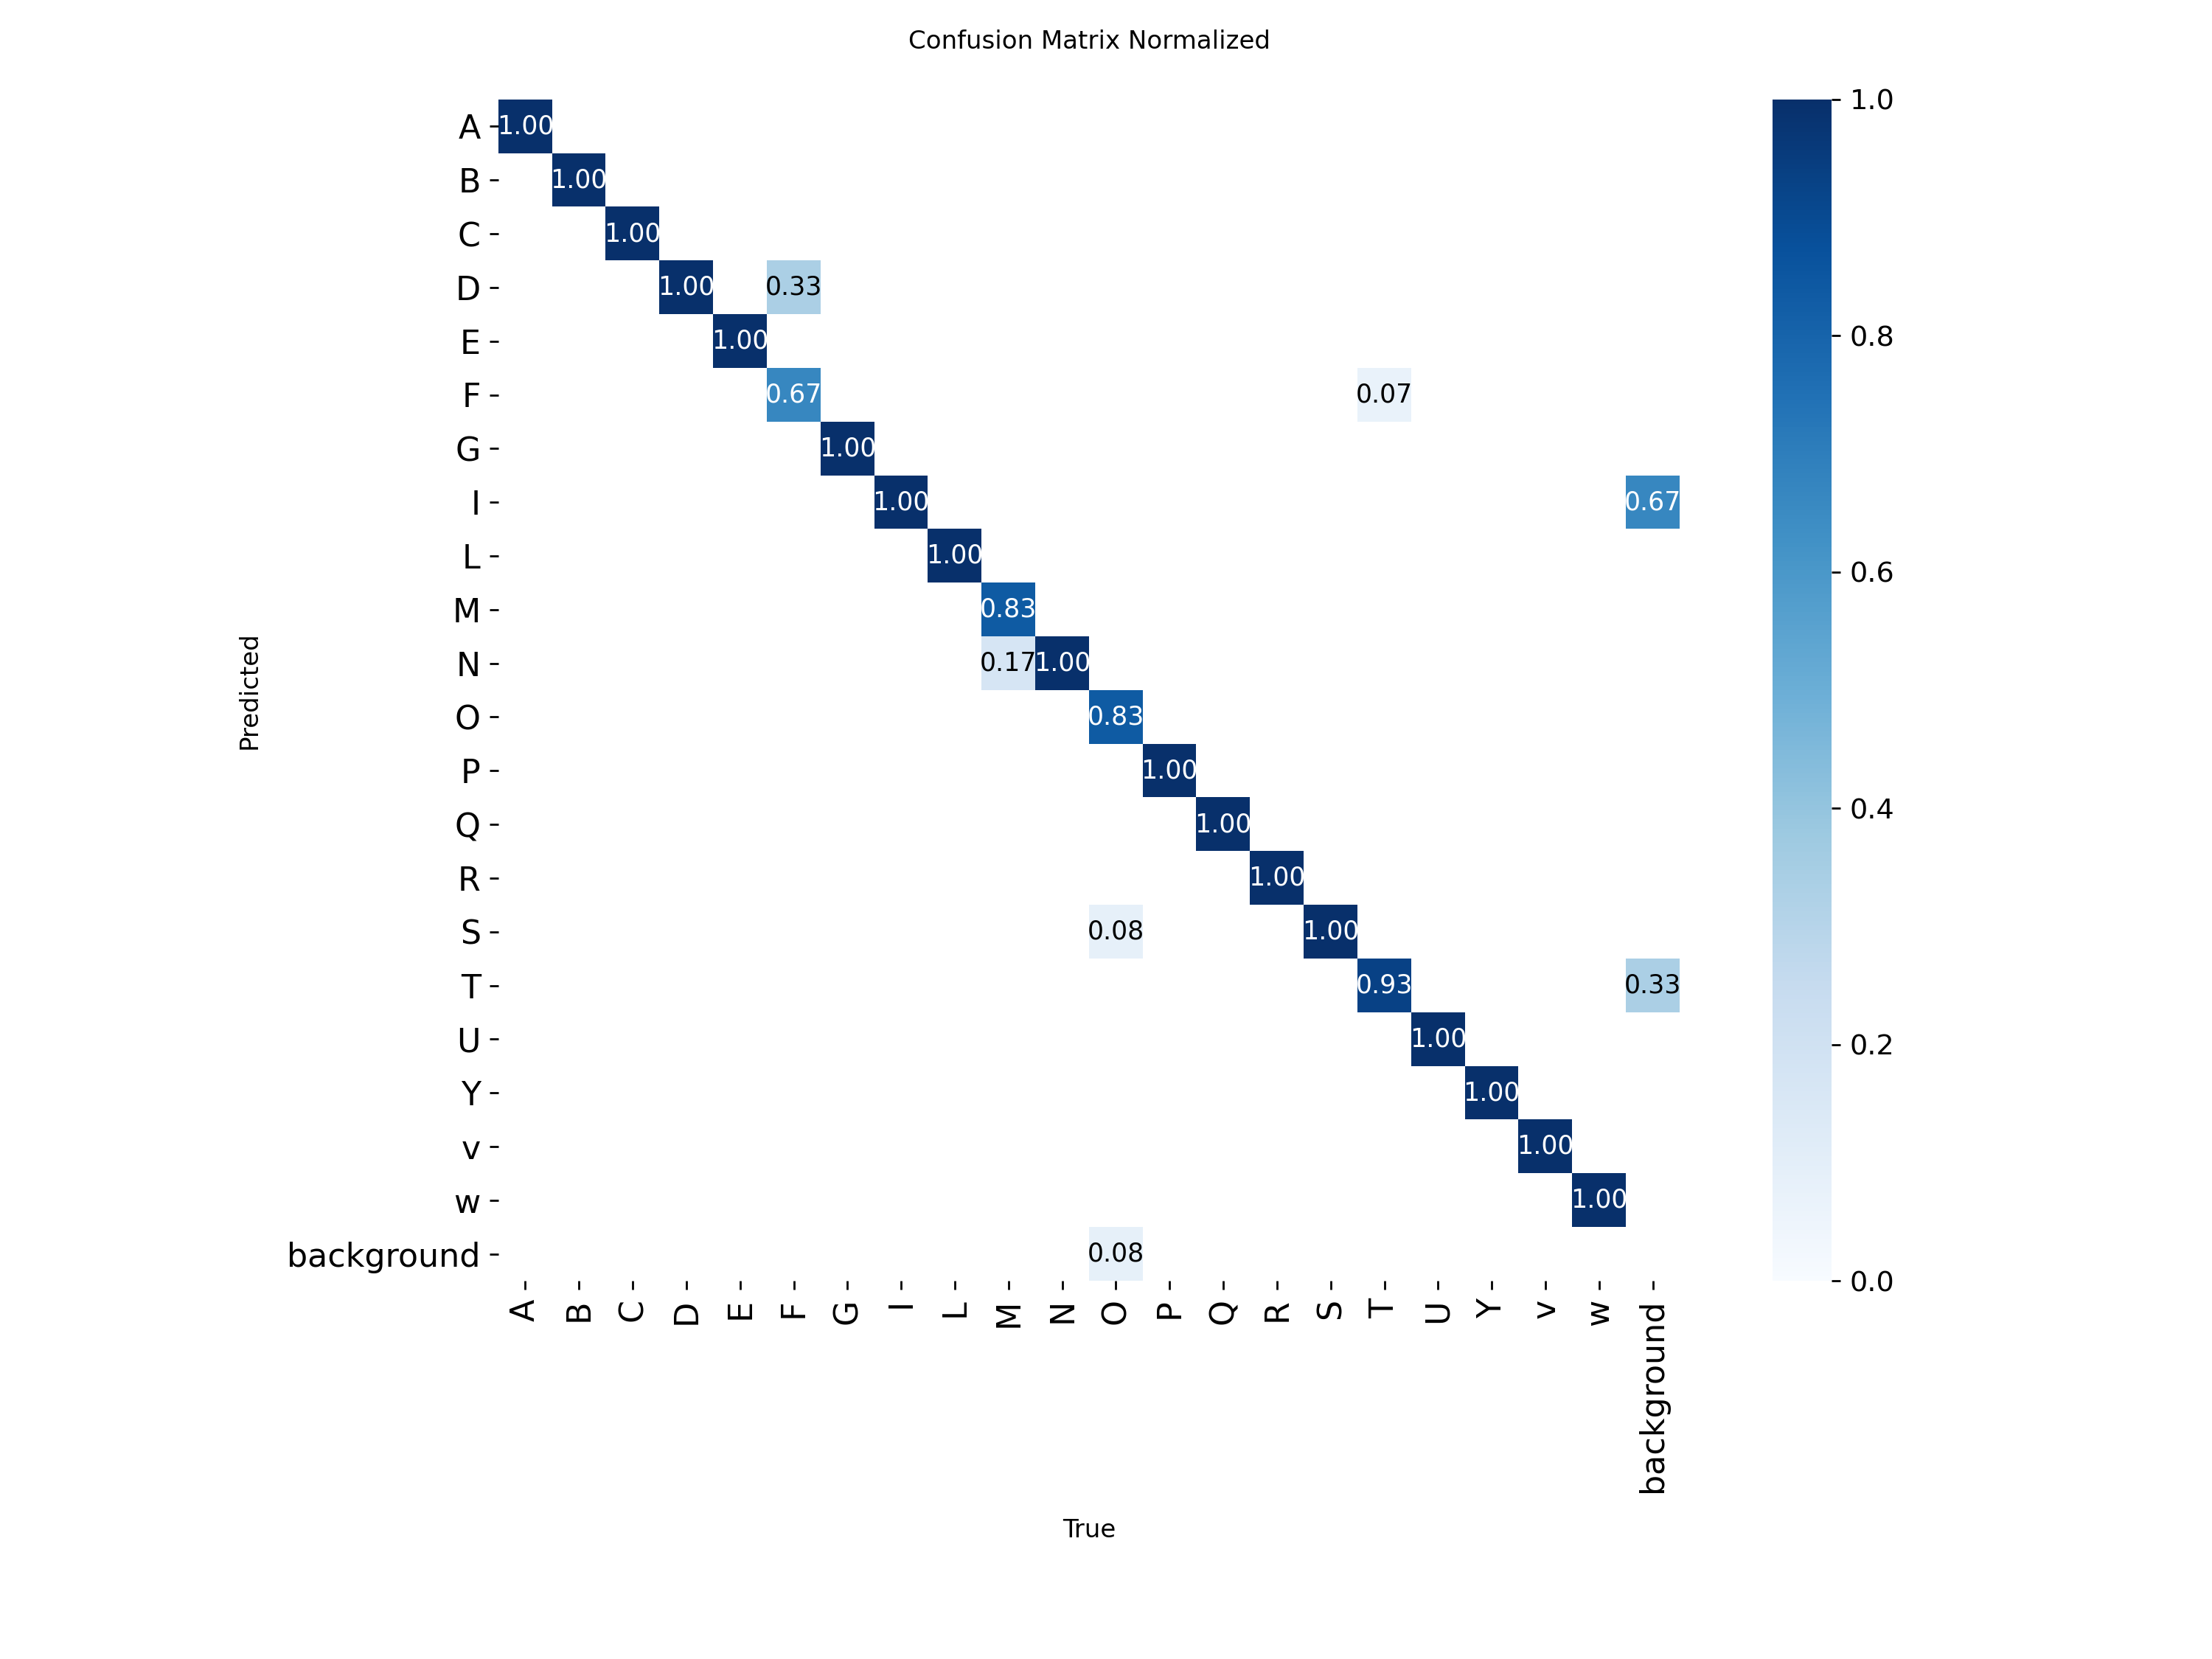

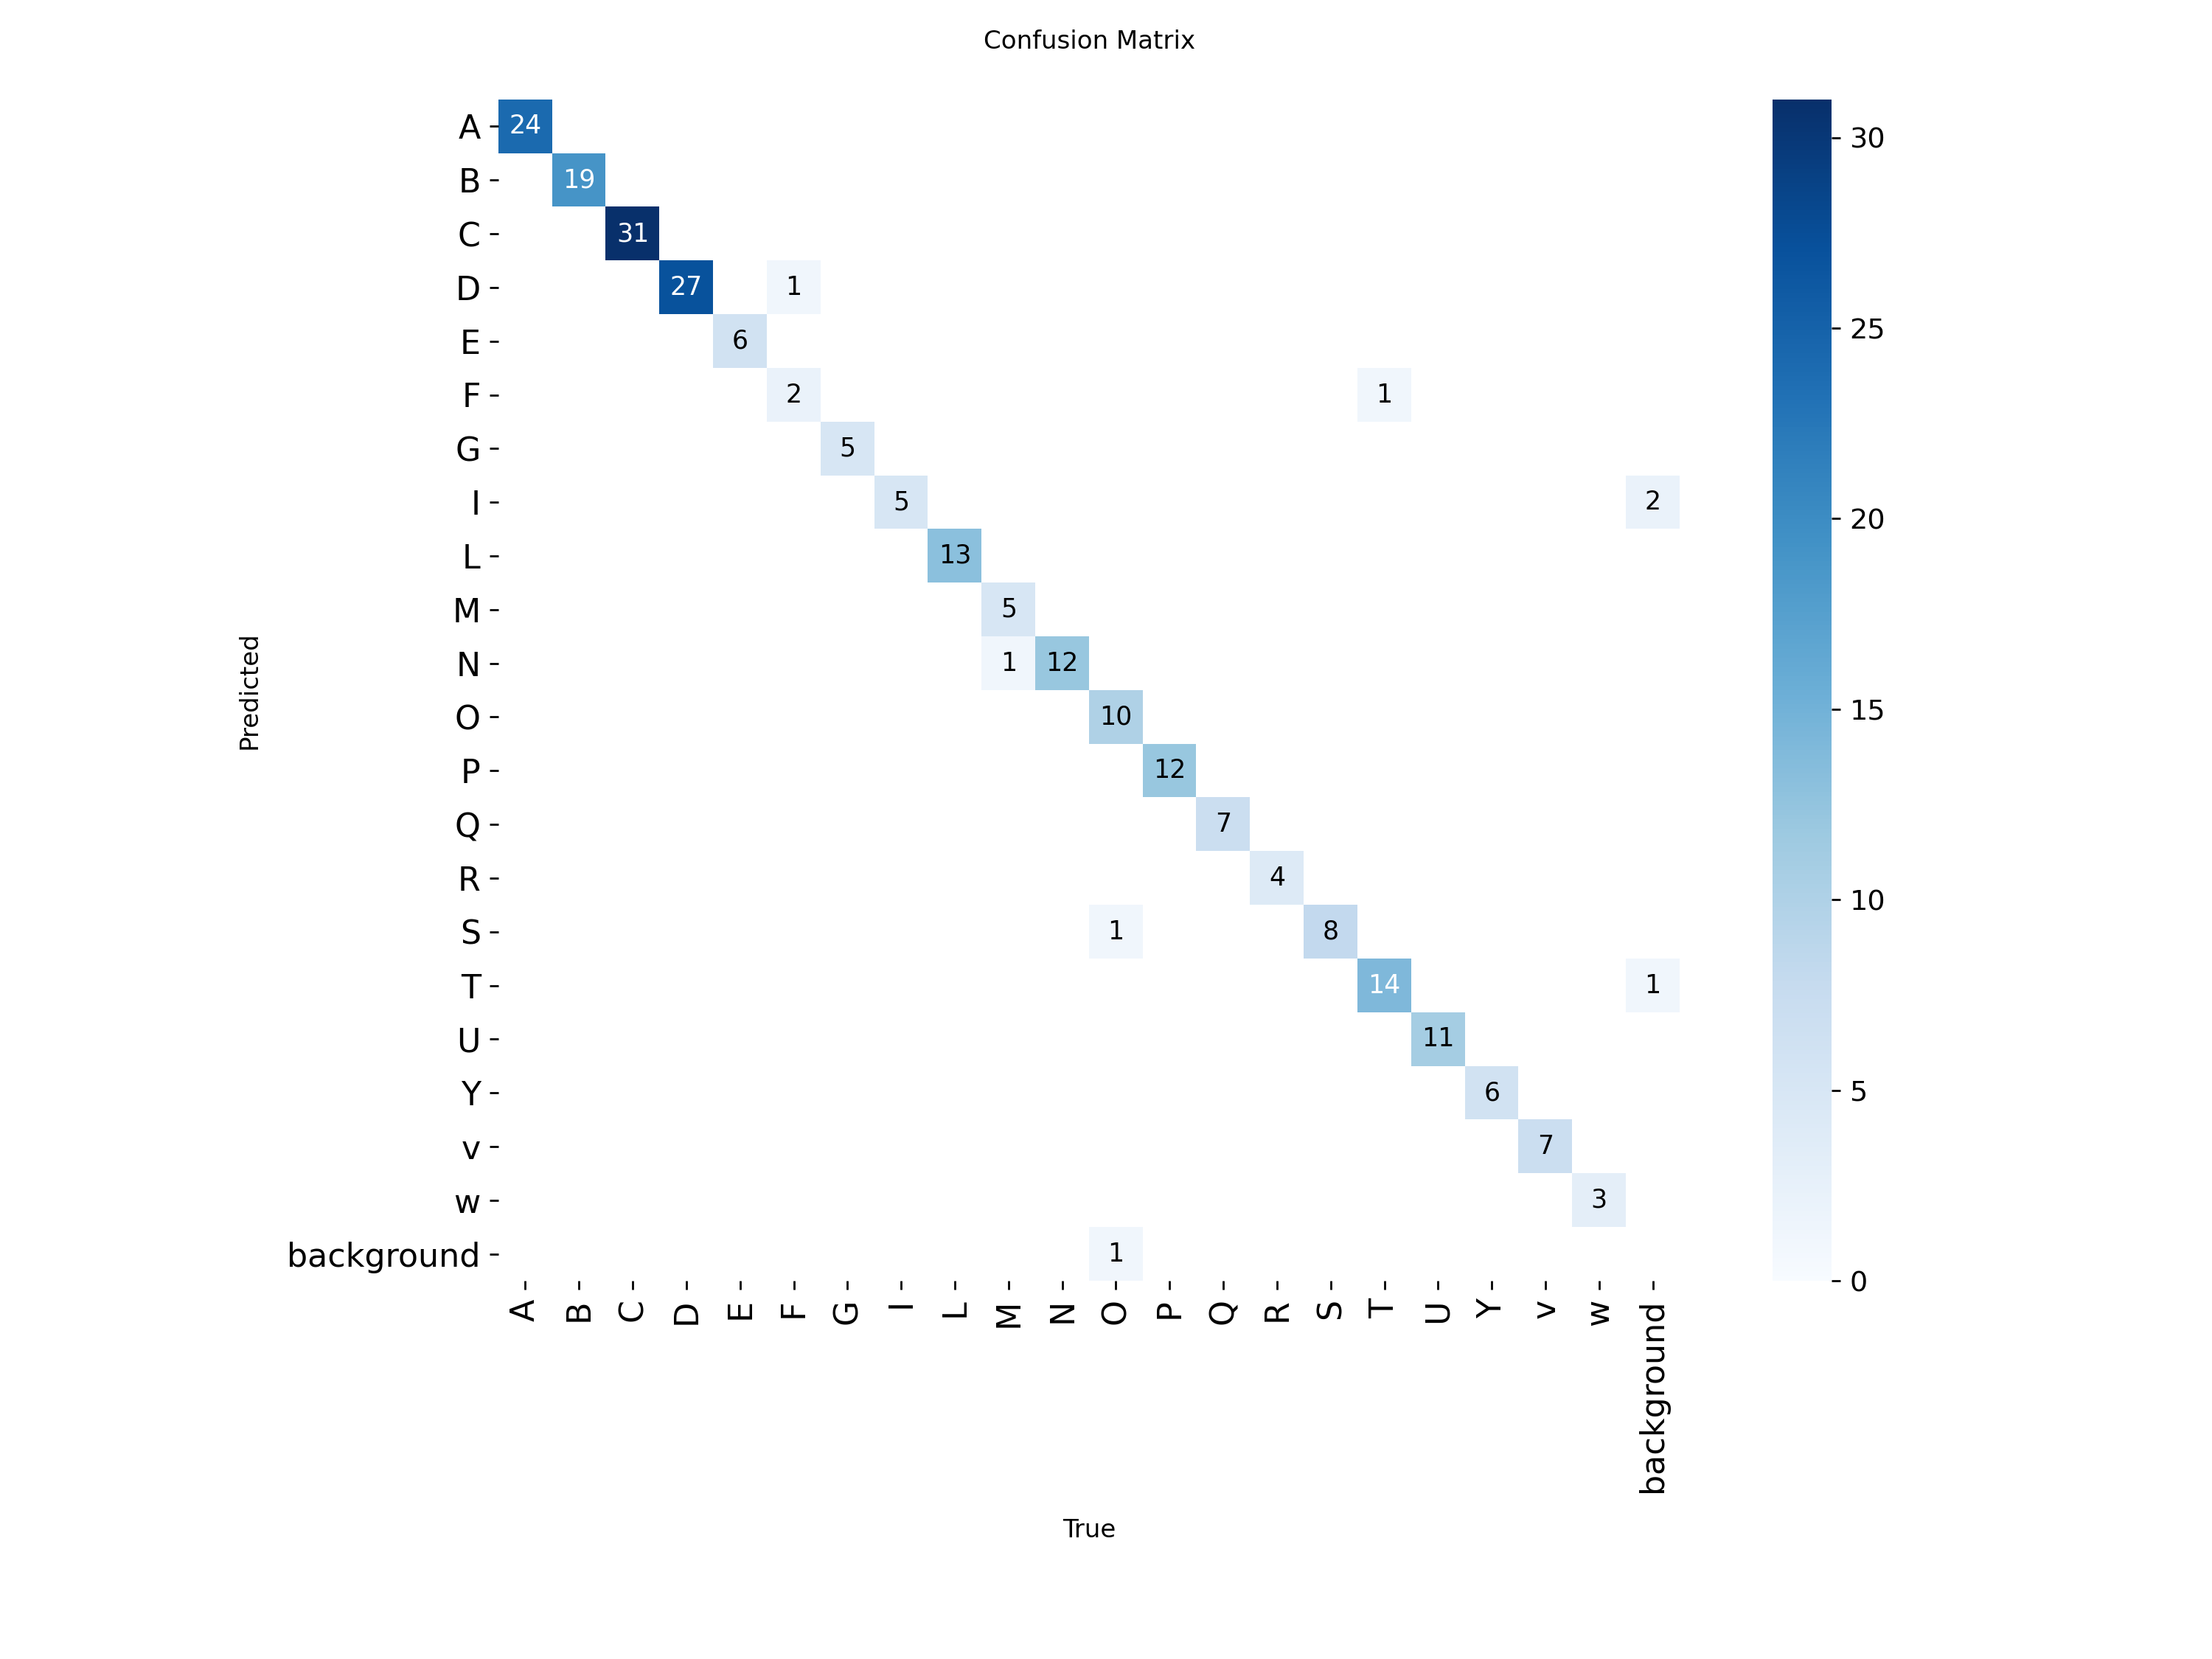

In [19]:
%cd {HOME}
!yolo task=detect mode=val model={last_run}/weights/best.pt data={dataset.location}/data.yaml conf=0.25 plots=True name=val_conf025 exist_ok=True

from IPython.display import Image, display

display(Image(filename=f'{HOME}/runs/detect/val_conf025/confusion_matrix_normalized.png', width=700))
display(Image(filename=f'{HOME}/runs/detect/val_conf025/confusion_matrix.png', width=700))

/kaggle/working


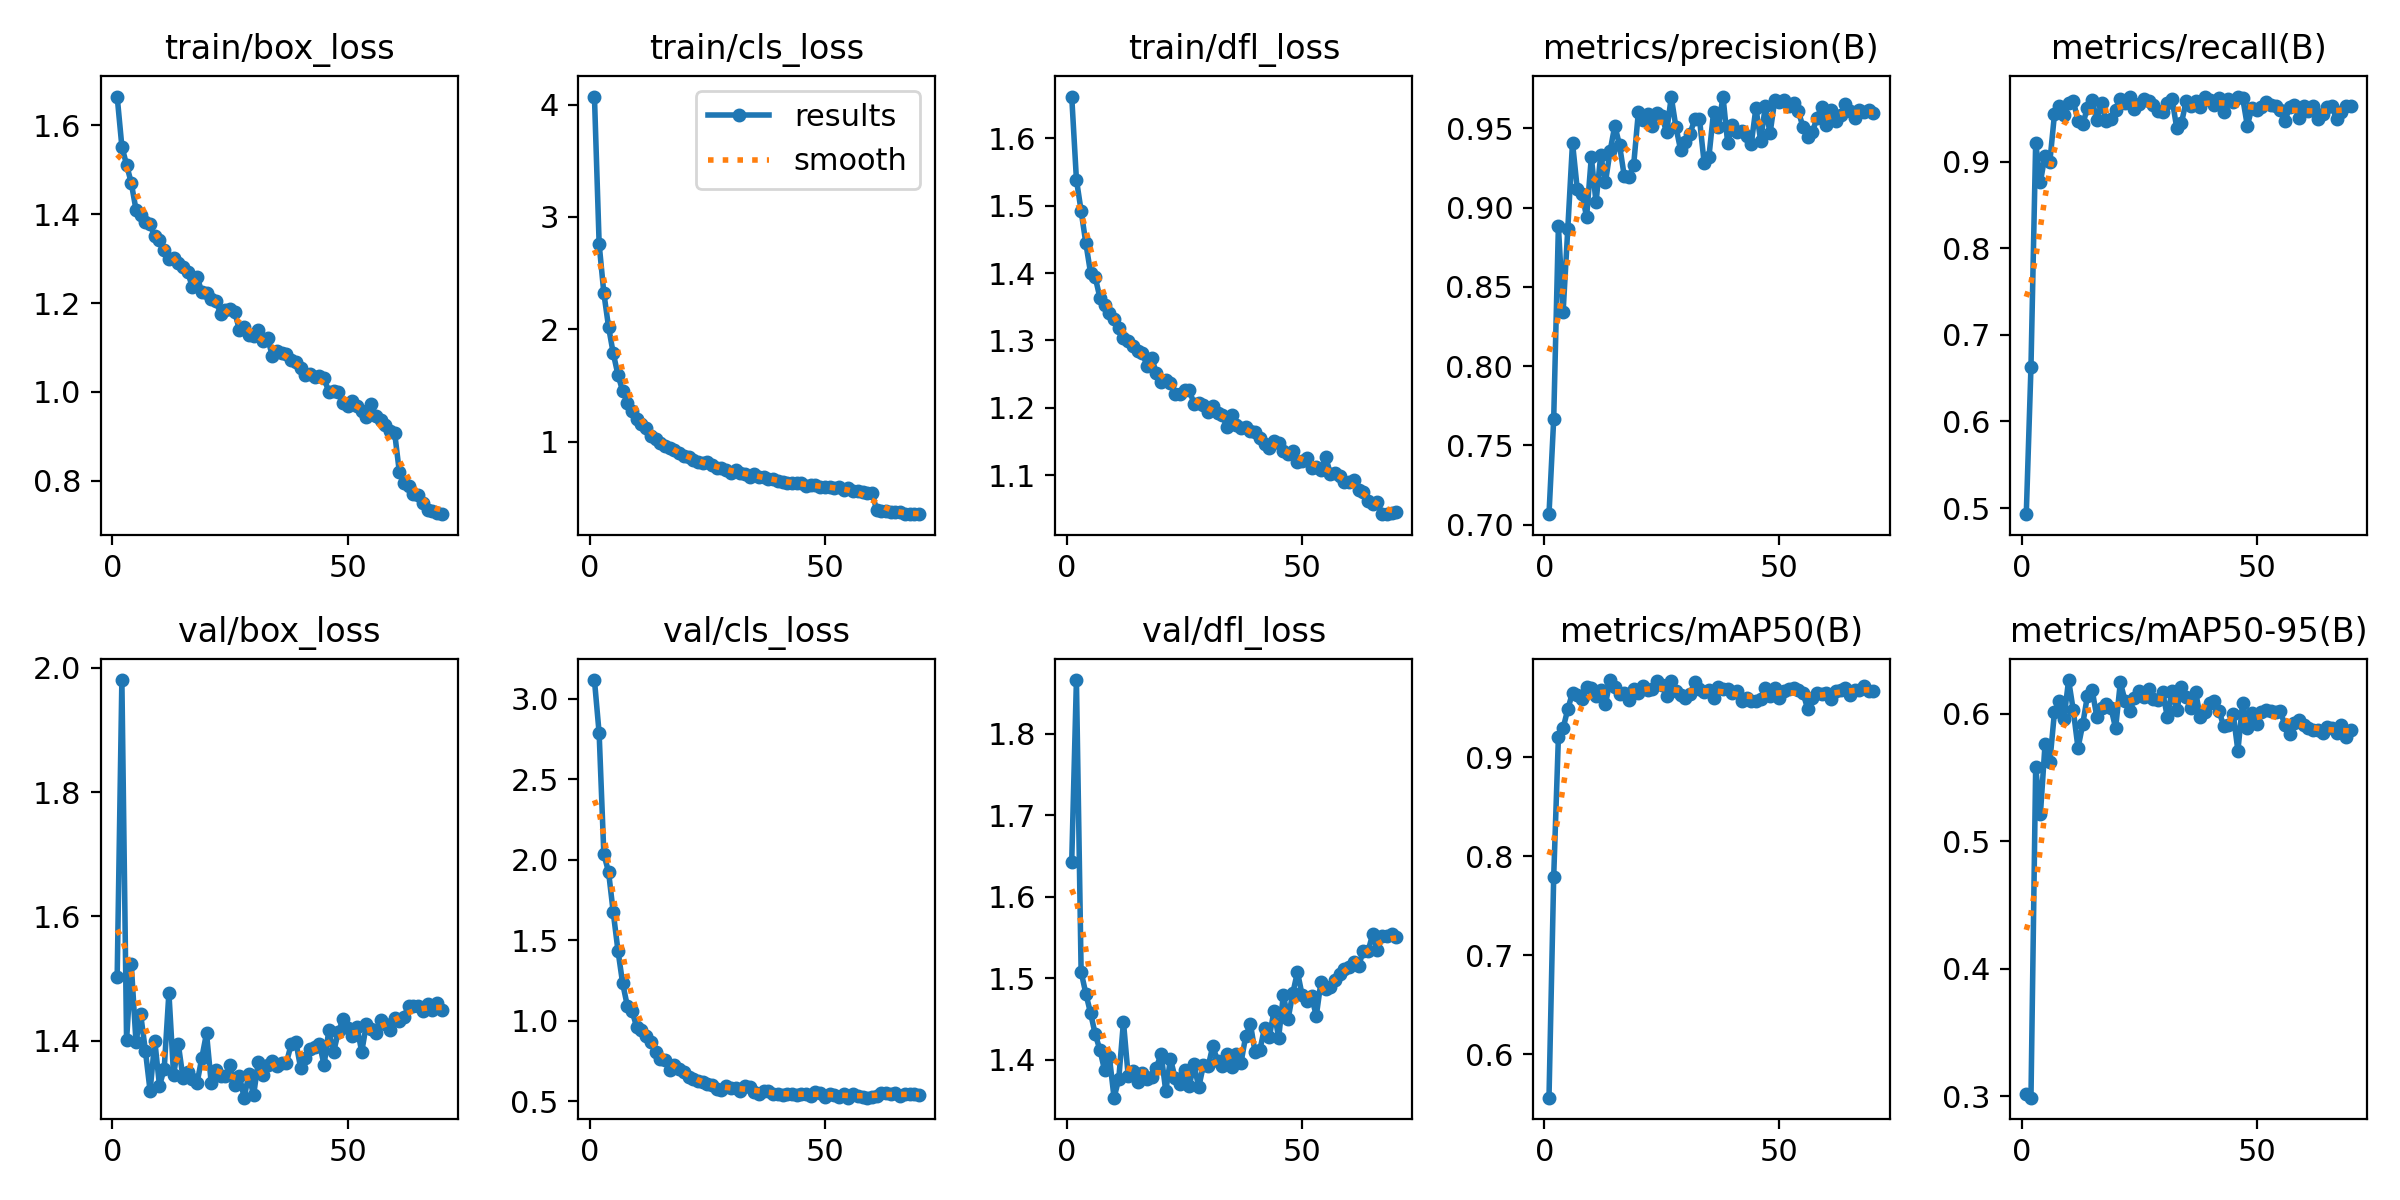

In [20]:
%cd {HOME}
Image(filename=f'{last_run}/results.png', width=600)

/kaggle/working


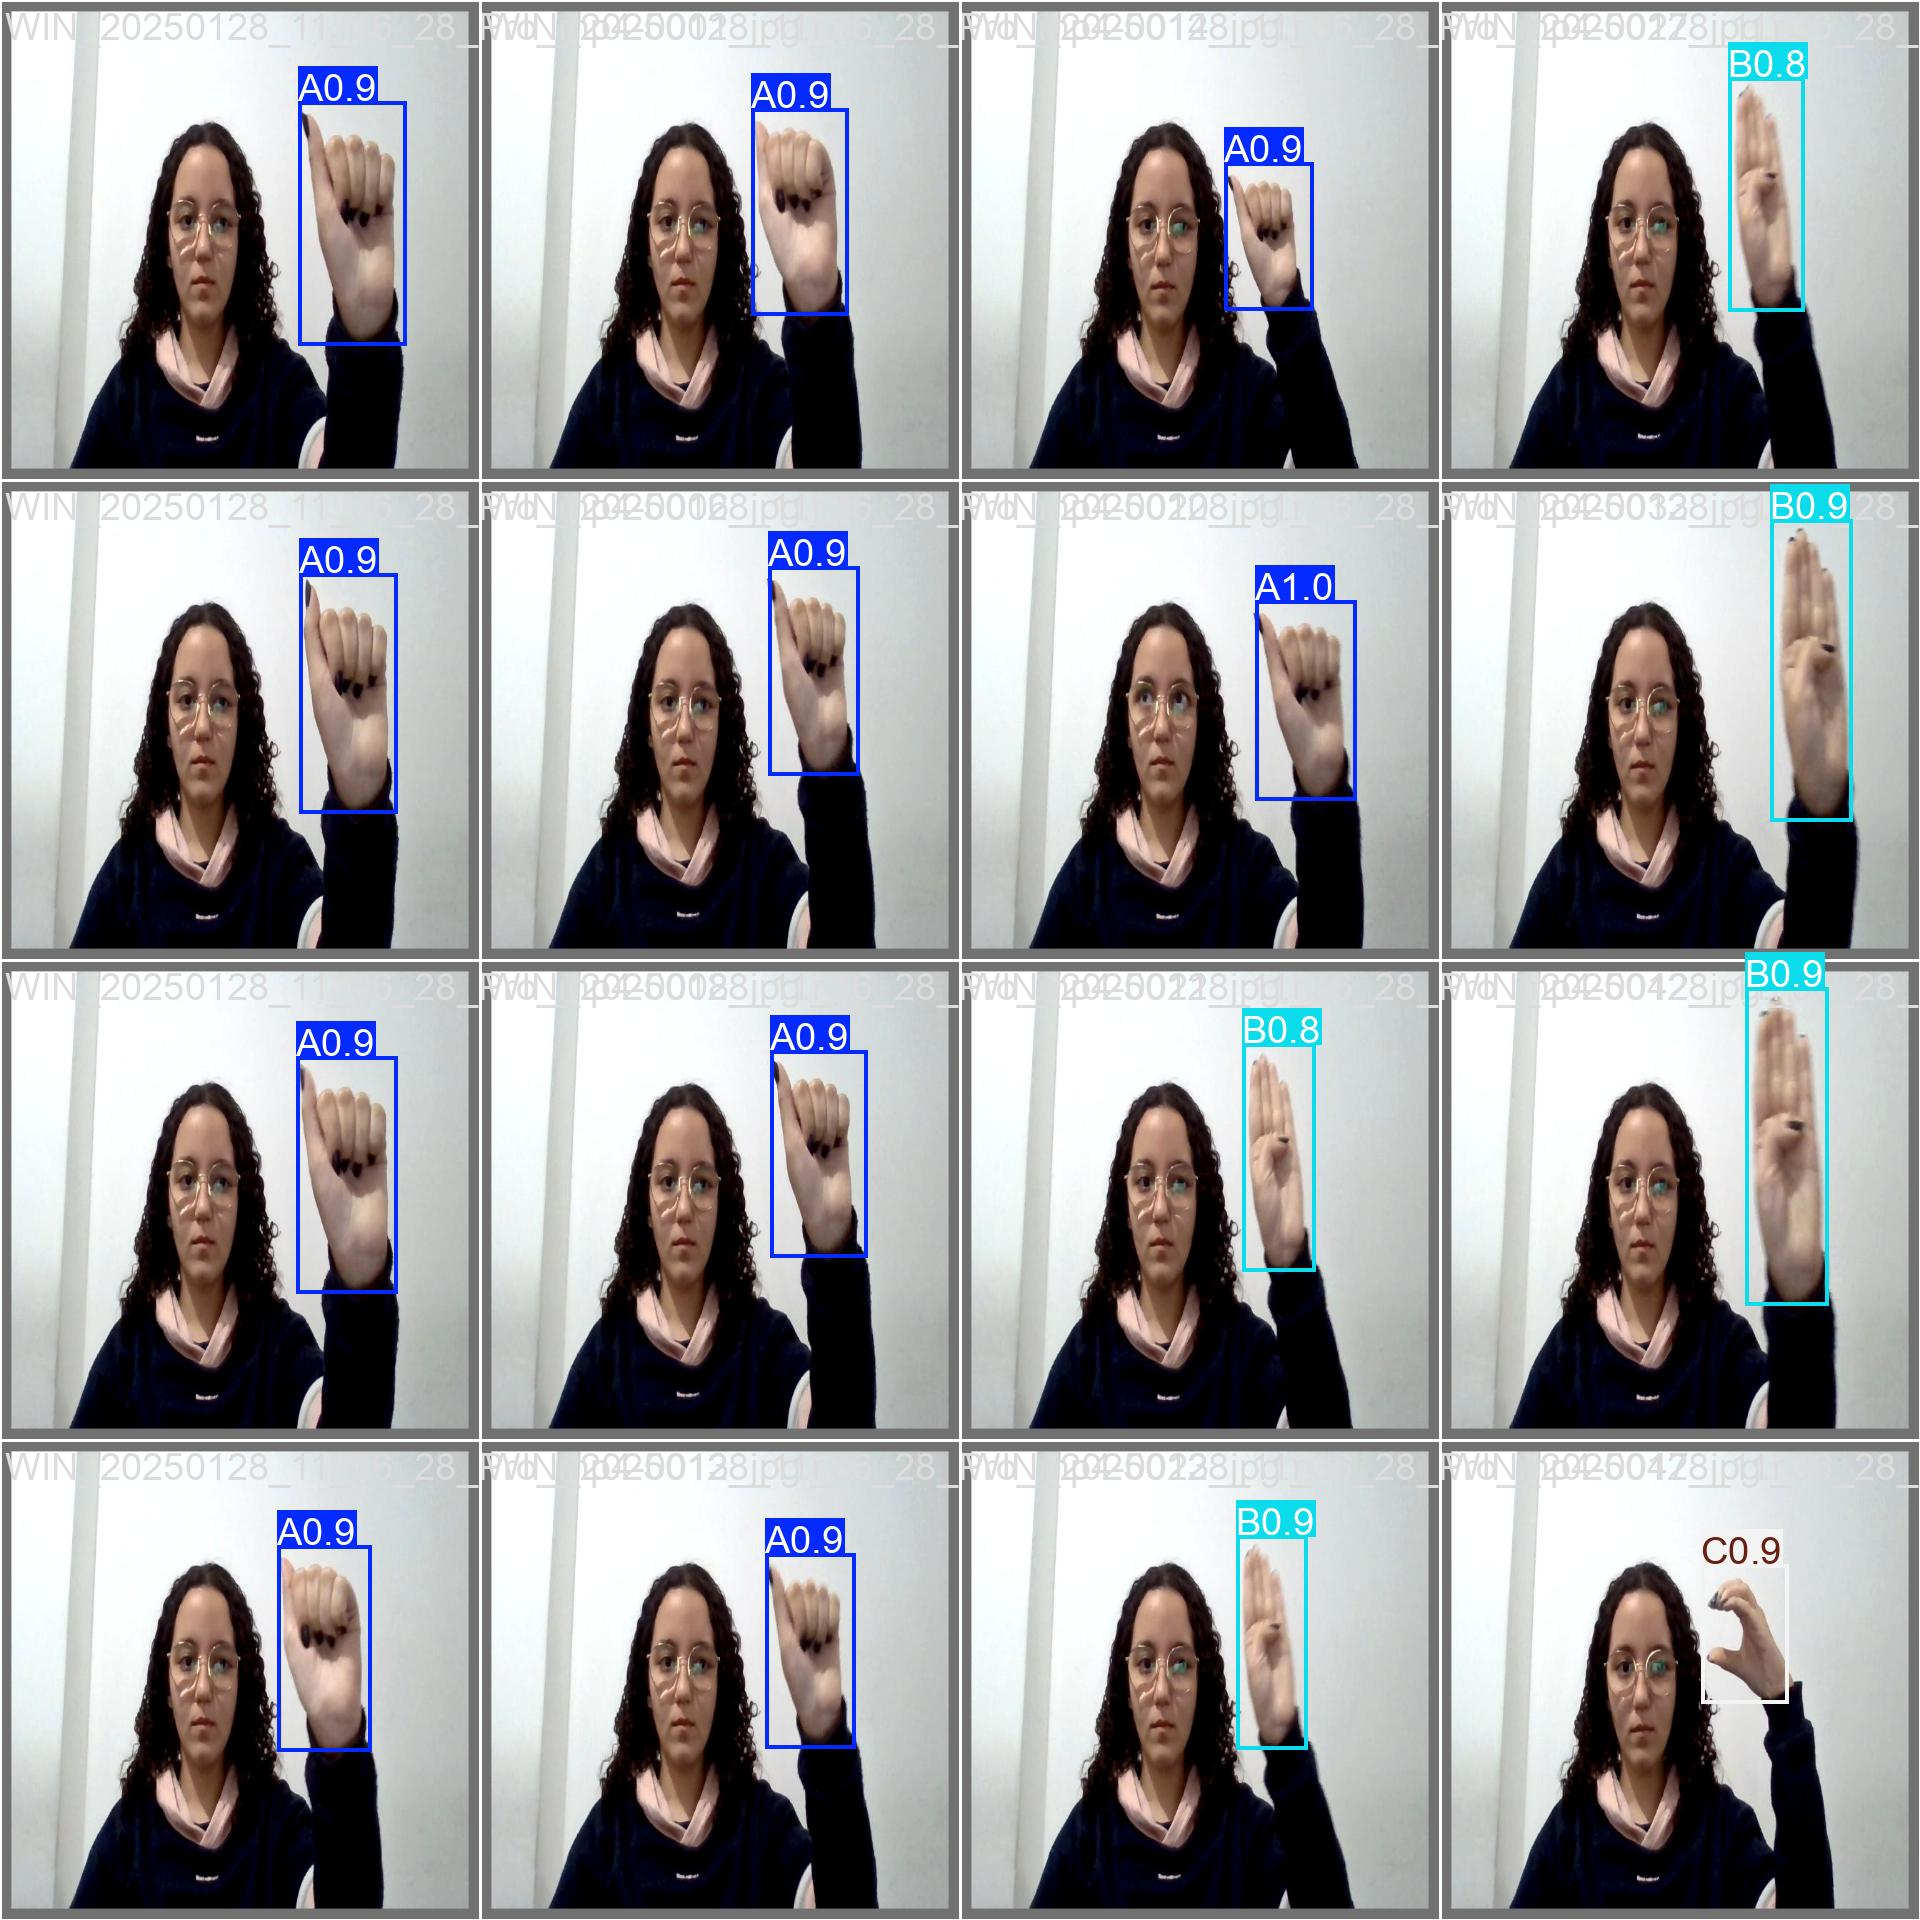

In [21]:
%cd {HOME}
Image(filename=f'{last_run}/val_batch0_pred.jpg', width=600)

In [22]:
%cd {HOME}

!yolo task=detect mode=val model={last_run}/weights/best.pt data={dataset.location}/data.yaml

/kaggle/working
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,009,743 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1009.3±262.1 MB/s, size: 29.3 KB)
val: Scanning /kaggle/working/Libras-proprio-2/valid/labels.cache... 238 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 238/238 39.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.9it/s 3.1s0.1s
                   all        238        236      0.932      0.968       0.97      0.627
                     A         24         24      0.978          1      0.995      0.682
                     B         19         19      0.973          1      0.995      0.743
                     C         31         31      0.987          1      0.995      0.696
                     D         27         27      0.947          1      0.995      0.615
            

In [29]:
%cd {HOME}
!yolo task=detect mode=predict model={HOME}/runs/detect/train-2/weights/best.pt conf=0.5 source={dataset.location}/test/images save=True name=pred_final exist_ok=True

/kaggle/working
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,009,743 parameters, 0 gradients, 8.1 GFLOPs

image 1/118 /kaggle/working/Libras-proprio-2/test/images/WIN_20250128_11_36_28_Pro_mp4-0004_jpg.rf.3f012b0442116de06546bbaa39c6c51b.jpg: 640x640 1 A, 7.3ms
image 2/118 /kaggle/working/Libras-proprio-2/test/images/WIN_20250128_11_36_28_Pro_mp4-0012_jpg.rf.cca334ee01c4e52f8a0b78892cb2625a.jpg: 640x640 1 A, 7.6ms
image 3/118 /kaggle/working/Libras-proprio-2/test/images/WIN_20250128_11_36_28_Pro_mp4-0026_jpg.rf.abca5e51bf4ad1818e2f2d98e370cc4c.jpg: 640x640 1 A, 7.4ms
image 4/118 /kaggle/working/Libras-proprio-2/test/images/WIN_20250128_11_36_28_Pro_mp4-0044_jpg.rf.347b03ac6a975b42b2ec3bf57b78d80e.jpg: 640x640 1 B, 7.2ms
image 5/118 /kaggle/working/Libras-proprio-2/test/images/WIN_20250128_11_36_28_Pro_mp4-0086_jpg.rf.fefebb7625727c618a80a88d3bc9860a.jpg: 640x640 1 C, 7.4ms
image 6/118 /kaggle/working/Libras-prop

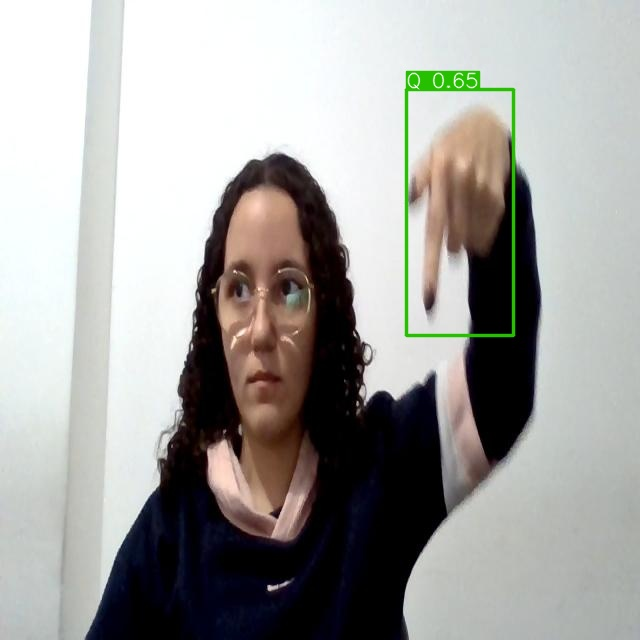

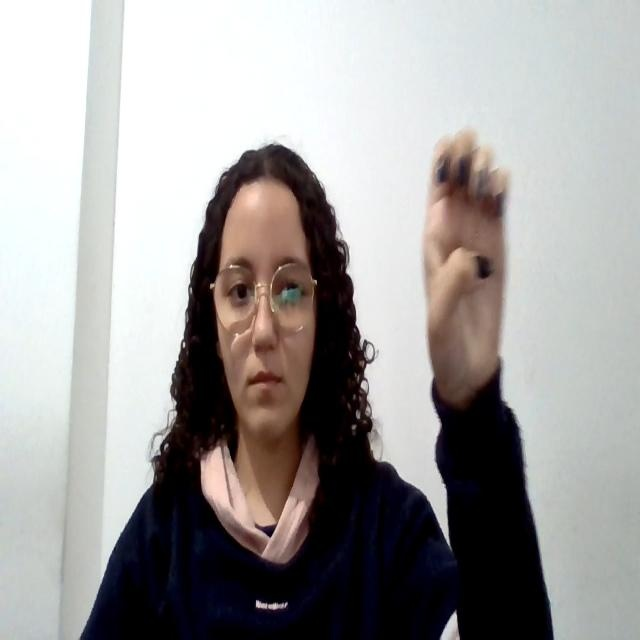

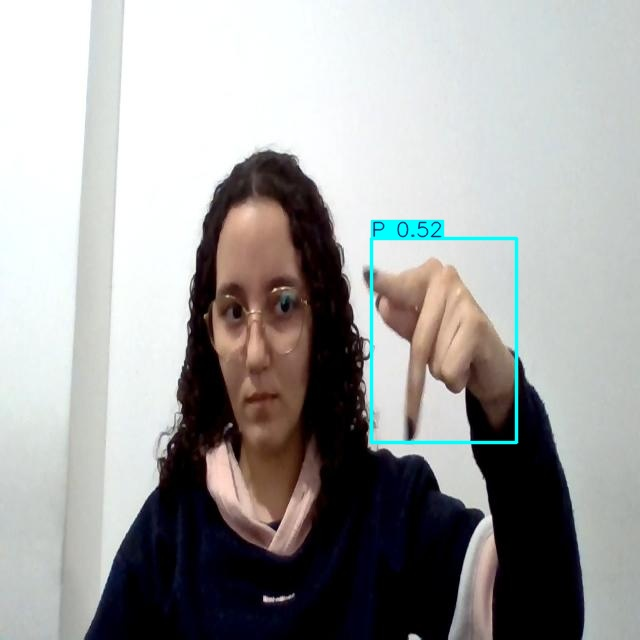

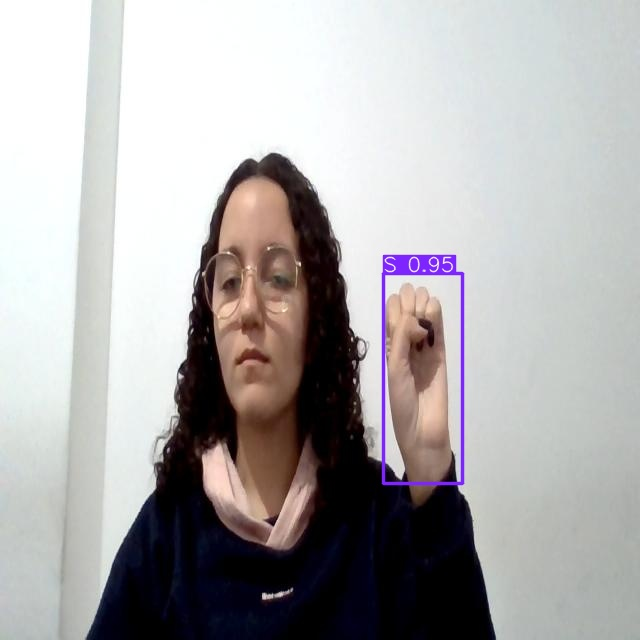

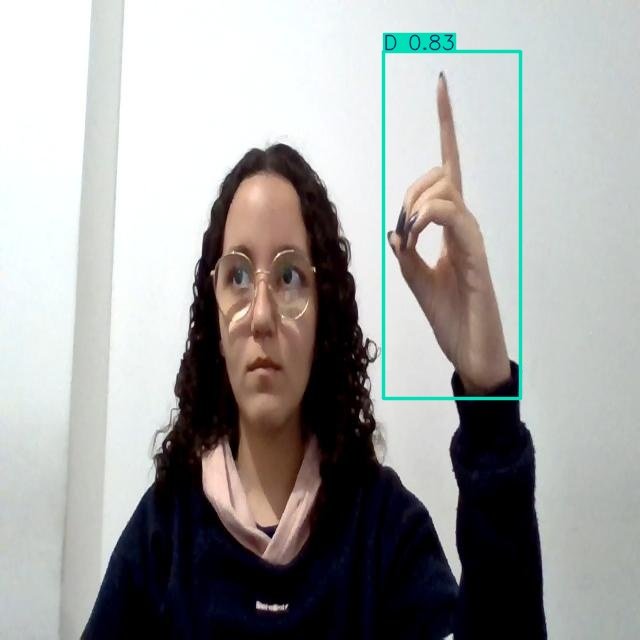

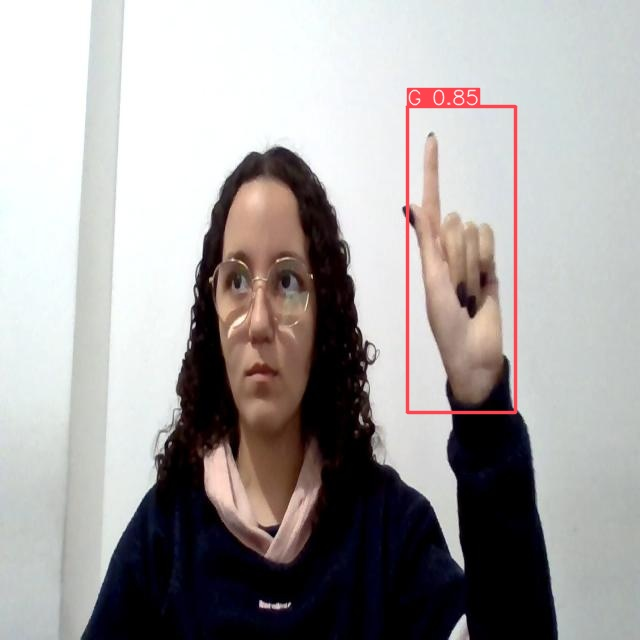

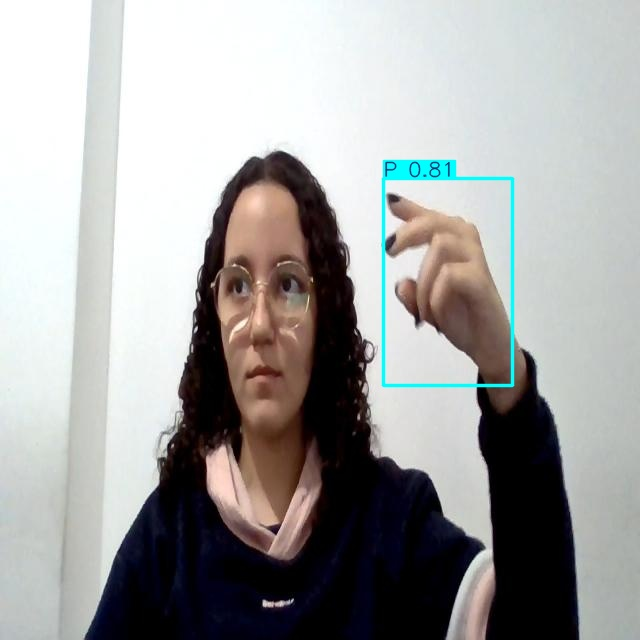

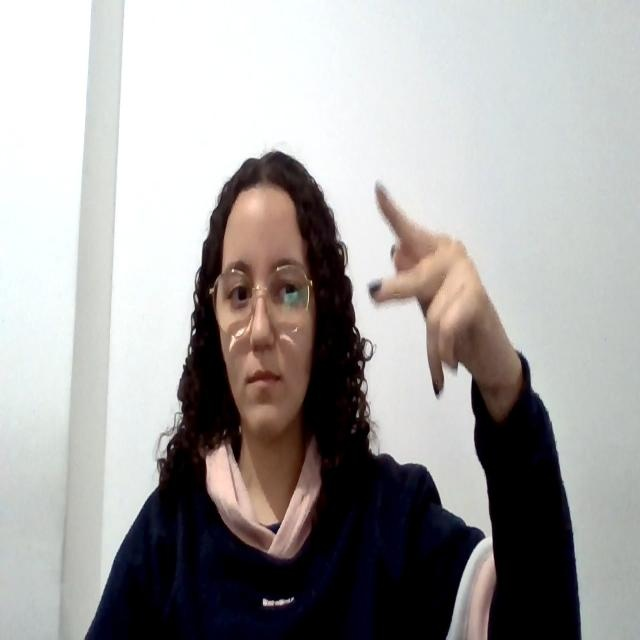

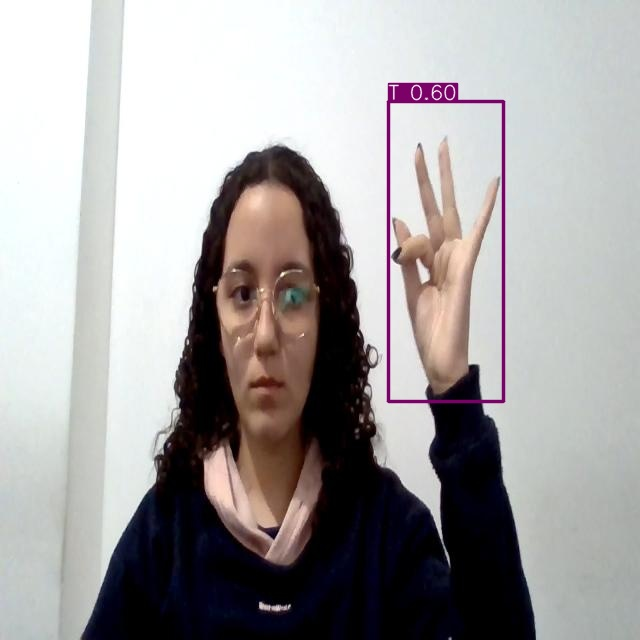

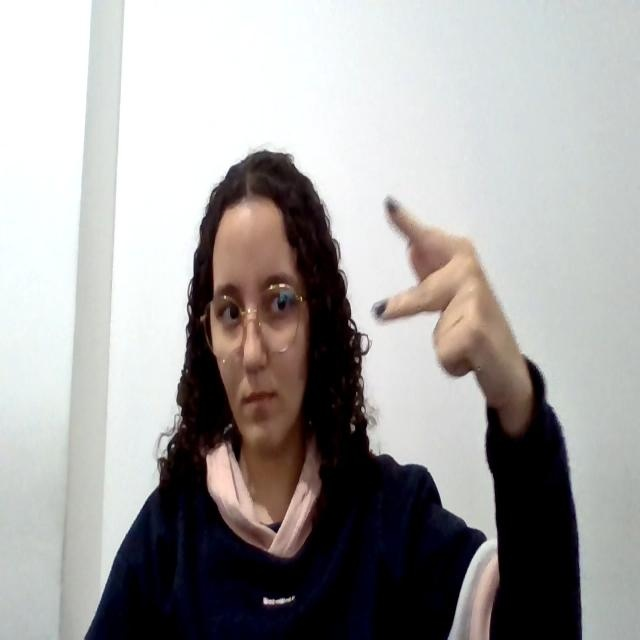

In [34]:
import glob
from IPython.display import Image, display

for image_path in glob.glob(f'{HOME}/runs/detect/pred_final/*.jpg')[:10]:
      display(Image(filename=image_path, width=600))
      print("\n")